# Intro

* How to integrate gradeint clipping, learning-rate schedulling, and model fine-tuning.
* That appropriate parameter selection requires careful choices, consideration, understanding, visual inspection, and experimentation

# Data

In [3]:
!pip install -U datasets huggingface_hub fsspec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.9/203.9 kB 29.3 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 202

In [4]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")
dataset

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

# Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from transformers import BertModel, BertTokenizer
from transformers import get_cosine_schedule_with_warmup, get_linear_schedule_with_warmup

In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
bert = BertModel.from_pretrained('bert-base-uncased').to(device)
bert

In [ ]:
bert.embeddings.dropout.p

In [ ]:
tokenizer.vocab_size

More on model inputs and outputs

In [ ]:
text = 'Replace me with any text you like.'
tokens = tokenizer(text, return_tensors='pt').to(device)
tokens

In [ ]:
# $ get model output using specific inputs
output = bert(
    input_ids      = tokens['input_ids'],
    attention_mask = tokens['attention_mask']
)

output = bert(**tokens)

# Model

In [ ]:
class BertForBinaryClassification(nn.Module):
  def __init__(self, num_labels=2):
    super().__init__()

    # Load the pretrained BERT model
    self.bert = BertModel.from_pretrained('bert-base-uncased')

    # classification head that converts the 768-d pooled output into 2 final outputs
    self.classifier = nn.Linear(768,2)
    self.dropout    = nn.Dropout(self.bert.embeddings.dropout.p) # 10%

    # initialize the weights and biases
    nn.init.xavier_uniform_(self.classifier.weight)
    nn.init.zeros_(self.classifier.bias)

  def forward(self, input_ids, attention_mask=None, token_type_ids=None):

    # forward pass through the downloaded (pretrained) BERT
    outputs = self.bert(
        input_ids = input_ids,
        attention_mask = attention_mask,
        token_type_ids = token_type_ids
    )

    # extract the pooled output and apply dropout
    pooled_output = self.dropout(outputs.pooler_output)

    # final push through the classification layer
    logits = self.classifier(pooled_output)

    return logits

In [ ]:
# create an instance of the model and test it
model = BertForBinaryClassification().to(device)

# test the output
tokens = tokenizer(text, return_tensors='pt').to(device)
out = model(**tokens)
out

# Limit Data

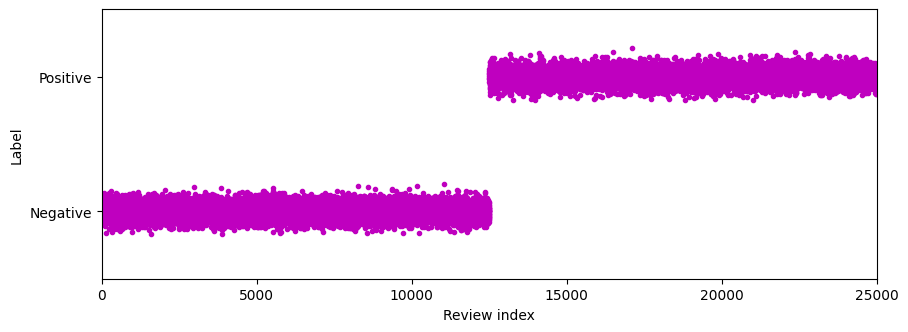

In [ ]:
plt.figure(figsize=(10,3.5))
plt.plot(dataset['train']['label'] + np.random.randn(len(dataset['train']))/20,'m.')

plt.gca().set(xlabel='Review index',
              ylabel = 'Label',
              yticks = [0,1],
              yticklabels = ['Negative', 'Positive'],
              xlim = [0, len(dataset['train'])],
              ylim=[-.5,1.5])
plt.show()

In [ ]:
from datasets import DatasetDict

small_data = DatasetDict({
    split: dataset[split].select(range(10000, 15000)) for split in ['train', 'test']
})
small_data

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 5000
    })
})

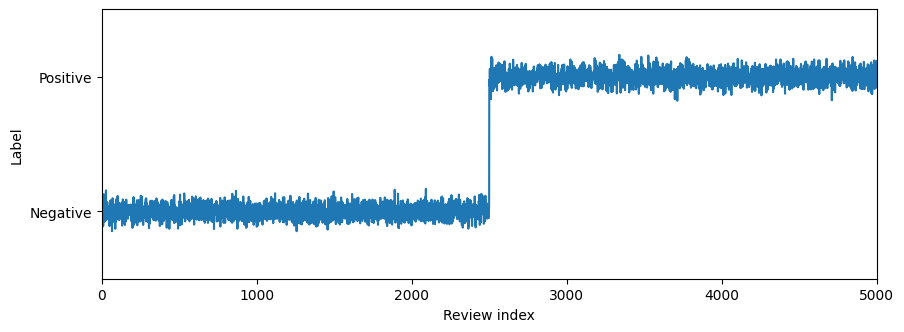

In [ ]:
# confirm we still have both categories
plt.figure(figsize=(10, 3.5))

plt.plot(
    small_data['train']['label']
    + np.random.randn(len(small_data['train'])) / 20
)

plt.gca().set(
    xlabel='Review index',
    ylabel='Label',
    yticks=[0, 1],
    yticklabels=['Negative', 'Positive'],
    xlim=[0, len(small_data['train'])],
    ylim=[-.5, 1.5]
)

plt.show()

# Text Tokenization with Padding

In [ ]:
first_try = tokenizer(dataset['train'][0]['text'])

# but this is better b/c reviews have differing lenghts
better = tokenizer(
    dataset['train'][0]['text'], # the text to tokenize
    max_length = 512,
    padding    = 'max_length', # using pad_token to reach max_len
    truncation = True
)

print(f'Naive\' tokenization (N = {len(first_try["input_ids"])})')
print(f'{first_try['input_ids']}')

print(f"\nBetter tokenization (N={len(better['input_ids'])}):")
print(f"{better['input_ids']}")

Naive' tokenization (N = 363)
[101, 1045, 12524, 1045, 2572, 8025, 1011, 3756, 2013, 2026, 2678, 3573, 2138, 1997, 2035, 1996, 6704, 2008, 5129, 2009, 2043, 2009, 2001, 2034, 2207, 1999, 3476, 1012, 1045, 2036, 2657, 2008, 2012, 2034, 2009, 2001, 8243, 2011, 1057, 1012, 1055, 1012, 8205, 2065, 2009, 2412, 2699, 2000, 4607, 2023, 2406, 1010, 3568, 2108, 1037, 5470, 1997, 3152, 2641, 1000, 6801, 1000, 1045, 2428, 2018, 2000, 2156, 2023, 2005, 2870, 1012, 1026, 7987, 1013, 1028, 1026, 7987, 1013, 1028, 1996, 5436, 2003, 8857, 2105, 1037, 2402, 4467, 3689, 3076, 2315, 14229, 2040, 4122, 2000, 4553, 2673, 2016, 2064, 2055, 2166, 1012, 1999, 3327, 2016, 4122, 2000, 3579, 2014, 3086, 2015, 2000, 2437, 2070, 4066, 1997, 4516, 2006, 2054, 1996, 2779, 25430, 14728, 2245, 2055, 3056, 2576, 3314, 2107, 2004, 1996, 5148, 2162, 1998, 2679, 3314, 1999, 1996, 2142, 2163, 1012, 1999, 2090, 4851, 8801, 1998, 6623, 7939, 4697, 3619, 1997, 8947, 2055, 2037, 10740, 2006, 4331, 1010, 2016, 2038, 3348, 2007,

In [ ]:
def tokenize_function(one_sample):
  return tokenizer(
      one_sample['text'],
      max_length = 512,
      padding = 'max_length',
      truncation = True # truncate sequences longer than max_length
  )

# apply tokenization func
tokenized_dataset = small_data.map(tokenize_function, batched = True)
tokenized_dataset

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5000
    })
})

# DataLoaders

In [ ]:
# remove text pair
tokenized_dataset = tokenized_dataset.remove_columns(['text'])

# change format to pytorch tensors
tokenized_dataset.set_format('torch', columns = ['input_ids', 'attention_mask', 'label'])

# create DataLoaders for training and testing
train_dataloader = DataLoader(tokenized_dataset['train'], shuffle=True, batch_size = 32)
test_dataloader  = DataLoader(tokenized_dataset['test'], batch_size = 32)

In [ ]:
X = next(iter(train_dataloader))
X

{'label': tensor([0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
         1, 1, 0, 1, 1, 0, 1, 1]),
 'input_ids': tensor([[  101,  4393, 22330,  ...,     0,     0,     0],
         [  101,  2023,  2186,  ...,     0,     0,     0],
         [  101,  1037,  2200,  ...,     0,     0,     0],
         ...,
         [  101,  2017,  2035,  ...,  2069,  1996,   102],
         [  101,  1005,  1996,  ...,  1045,  2228,   102],
         [  101,  2106, 12834,  ...,     0,     0,     0]]),
 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         ...,
         [1, 1, 1,  ..., 1, 1, 1],
         [1, 1, 1,  ..., 1, 1, 1],
         [1, 1, 1,  ..., 0, 0, 0]])}

# Learning Rate Scheduler Toy Model

In [ ]:
# training steps
training_steps = 300

# create a "model" and an optimizer
optimizer = torch.optim.AdamW(nn.Linear(10,10).parameters(), lr=3e-5)

# learning rate scheduler
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps = int(training_steps*.05),
    num_training_steps = int(training_steps * 1.5),
)

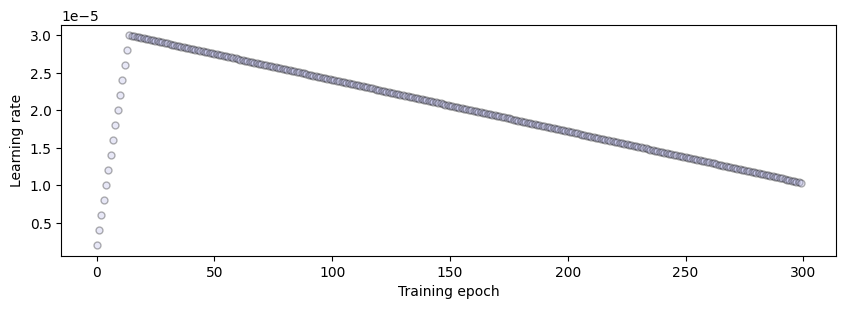

In [ ]:
# quick test to see the learning rates
lrs = np.zeros(training_steps)

for i in range(training_steps):

  optimizer.step()
  scheduler.step()
  lrs[i] = scheduler.get_last_lr()[0]

plt.figure(figsize=(10,3))
plt.plot(lrs, 'ko', markersize=5, markerfacecolor=[.7,.7,.9], alpha=.3)
plt.gca().set(xlabel='Training epoch', ylabel='Learning rate')
plt.show()

# Fine-Tune

In [ ]:
# training steps
training_steps = 300

# create a "model" and an optimizer
optimizer = torch.optim.AdamW(nn.Linear(10,10).parameters(), lr=3e-5)

# learning rate scheduler
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps = int(training_steps*.05),
    num_training_steps = int(training_steps * 1.5),
)

# optimizer and loss
optimizer = torch.optim.AdamW(model.parameters(), lr = 1e-5)
loss_fn = nn.CrossEntropyLoss() # ce loss for multi-class classification

In [ ]:
model.classifier.weight.grad.shape

AttributeError: 'NoneType' object has no attribute 'shape'

In [ ]:
model.classifier

In [ ]:
# norm storage
norms = torch.zeros((training_steps,2))

train_losses = torch.zeros(training_steps)
train_accuracy = torch.zeros(training_steps)
test_losses = torch.zeros(training_steps)
test_accuracy = torch.zeros(training_steps)

for sampli in range(training_steps):

  epoch_loss = 0
  epoch_acc  = 0

  batch = next(iter(train_dataloader))

  # move it to GPU
  tokenz  = batch['input_ids'].to(device)
  att_msk = batch['attention_mask'].to(device)
  labels  = batch['label'].to(device)

  # clear the previous gradeints
  optimizer.zero_grad()

  # forward pass and get model preds
  logits = model(tokenz, attention_mask=att_msk)
  pred_labels = torch.argmax(logits, dim=1)

  # calculate and store loss + avg acc
  train_loss = loss_fn(logits, labels)
  train_acc = (pred_labels == labels).sum().item()/train_dataloader.batch_size

  # store
  train_losses[sampli] = train_loss.item()
  train_accuracy[sampli] = train_acc

  # backward pass
  train_loss.backward()

  # store norm
  norms[sampli, 0] = torch.norm(model.bert.encoder.layer[7].output.dense.weight.grad).item()
  norms[sampli, 1] = torch.norm(model.classifier.weight.grad).item()

  # update the weights and teh lr
  nn.utils.clip_grad_norm_(model.parameters(), max_norm=1)
  optimizer.step()

  # update scheduler
  scheduler.step()

  if sampli % 20 == 0:

    model.eval()
    with torch.no_grad():

      # get a batch of data and move it to the GPU
      batch  = next(iter(test_dataloader))
      tokenz = batch['input_ids'].to(device)
      att_msk= batch['attention_mask'].to(device)
      labels = batch['label'].to(device)

      # forward pass and get model predictions
      logits = model(tokenz, attention_mask=att_msk)
      pred_labels = torch.argmax(logits, dim = 1)

      # calculate and store loss + accuracy
      loss = loss_fun(logits, labels)
      test_losses[sampli] = loss.item()
      test_accuracy[sampli] = (pred_labels == labels).sum().item()/train_dataloader.batch_size

      # report the results
      print(f'Sample {sampli:4}/{num_samples}, losses (train/test): {train_losses[sampli]}')

      model.train()

# Eval

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# plot the losses
axs[0].plot(train_losses,'ko',markerfacecolor=[.9,.7,.7],alpha=.5,label='Train')
axs[0].plot(range(0,num_samples,10),test_losses[::10],'ks-',
            markerfacecolor=[.7,.9,.7],markersize=8,alpha=.8,linewidth=3,label='Test')
axs[0].set(xlabel='Training sample',ylabel='Loss',title='Cross-entropy loss',xlim=[0,num_samples])
axs[0].legend()

# plot the prediction accuracy
axs[1].plot(100*train_accuracy,'ko',markerfacecolor=[.7,.7,.9],alpha=.5,label='Train')
axs[1].plot(range(0,num_samples,10),100*test_accuracy[::10],'ks-',
            markerfacecolor=[.7,.9,.7],markersize=8,alpha=.8,linewidth=3,label='Test')
axs[1].set(xlabel='Training sample',ylabel='Percent correct (%)',title='Prediction accuracy',xlim=[0,num_samples])
axs[1].legend()

plt.tight_layout()
plt.show()